# code_011 · Just-in-time mathematics for scientific models

**Book:** Chapter 2, section 2.5. **Scope:** a mathematics laboratory, with exact toy models and generated data. This is not a field-validation study or an exhaustive estimator-constructor lab. All imports, inputs and helpers are contained here.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt), then restart and run all cells. The reference environment is CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1 and Matplotlib 3.11.0, macOS ARM64 CPU. No data downloads, API keys, GPU or project imports are needed. Allow a minute for execution and 30–60 minutes for predictions and exercises. Actual runtime appears at the end and in [execution evidence](../CHAPTER_02_EXECUTION.md).

Read each prediction before revealing output. Controls here are coordinate choices, numerical-method settings and stated system/data assumptions; they are not collectively model hyperparameters. These constructed mechanism checks do not need a supervised train/test split. A later fitted predictive pipeline must learn scales and representations on training data only. See the [concept-to-code guide](../CHAPTER_02_GUIDE.md) and [stable code directory](../CODE_EXAMPLES.md#code_011).


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter(); SEED=202
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="integration"></a>
## Accumulation requires weights

Integrate q(x)=2x N/m along a one-metre interval. Its resultant force is one newton. The trapezoidal rule is exact for this linear function, including on an irregular grid. An unweighted mean is a mean over selected nodes, not necessarily a physical spatial average. Here that average happens to have the same numeric value as the integral only because length is one metre.

**Predict:** how does a cluster of nodes near x=0 distort the unweighted average? For a two-metre domain, what units and length factor must an average and integral have?


In [2]:
grid=np.array([0.,.01,.02,.1,.5,1.]);load=2*grid
integral=np.trapezoid(load,grid);unweighted=load.mean()
assert np.isclose(integral,1.) and not np.isclose(unweighted,1.)
print('Trapezoidal resultant [N]:',integral,'unweighted node mean [N/m]:',unweighted)
RESULTS['integral_N']=float(integral);RESULTS['unweighted_node_mean_N_per_m']=float(unweighted)
worksheet=pd.DataFrame([
 ['ODE rate','state at one time','time derivative plus initial state','integrator builds a trajectory'],
 ['PDE solution','position, time and fixed conditions','field value','initial/boundary conditions select solution'],
 ['Operator','an input field and declared coefficients','output field or trajectory','family of initial conditions']
],columns=['object','input','output or defining information','interpretation'])
assert set(worksheet.object)=={'ODE rate','PDE solution','Operator'};display(worksheet)


Trapezoidal resultant [N]: 1.0 unweighted node mean [N/m]: 0.5433333333333333


,object,input,output or defining information,interpretation
0,ODE rate,state at one time,time derivative plus initial state,integrator builds a trajectory
1,PDE solution,"position, time and fixed conditions",field value,initial/boundary conditions select solution
2,Operator,an input field and declared coefficients,output field or trajectory,family of initial conditions


<a id="diffusion"></a>
## Fixed-end diffusion: a stencil and matching matrix

Temperature deviation T evolves by T_t=kappa*T_xx on [0,1] m with zero endpoints, constant kappa=0.01 m²/s and no source. The explicit rule uses r=kappa*dt/dx². The interior matrix has diagonal 2 and off-diagonal -1; boundary connections remain in its diagonal. It differs from a path graph containing only interior nodes, whose endpoints have degree one. Reservoir boundaries allow heat to leave, so interior sum conservation would be the wrong check.

**Predict:** why does halving dx at fixed dt multiply r by four? Why must we not claim that a generic graph aggregation is a physical discretization?


In [3]:
kappa=.01;length=1.
def interior_laplacian(n):
 return 2*np.eye(n)-np.eye(n,k=1)-np.eye(n,k=-1)
def evolve(initial,r,steps):
 u=np.array(initial,dtype=float).copy();u[[0,-1]]=0.;history=[u.copy()]
 for _ in range(steps):
  u[1:-1]+=r*(u[:-2]-2*u[1:-1]+u[2:]);u[[0,-1]]=0.;history.append(u.copy())
 return np.array(history)
x=np.linspace(0,length,41);dx=x[1]-x[0];L=interior_laplacian(39)
initial=np.sin(np.pi*x)+.01*np.sin(39*np.pi*x);initial[[0,-1]]=0.
r=.4;one=evolve(initial,r,1)[1]
assert np.allclose(one[1:-1],initial[1:-1]-r*L@initial[1:-1])
A=np.eye(39,k=1)+np.eye(39,k=-1);graph_L=np.diag(A.sum(1))-A
assert np.allclose(graph_L@np.ones(39),0)
assert not np.allclose(L@np.ones(39),0)
assert np.allclose(L-graph_L,np.diag(np.r_[1.,np.zeros(37),1.]))
print('dx [m]:',dx,'dt [s] at r=.4:',r*dx**2/kappa,'matrix/stencil maximum difference:',np.max(abs(one[1:-1]-(initial[1:-1]-r*L@initial[1:-1]))))
RESULTS['stencil_matrix_max_error']=float(np.max(abs(one[1:-1]-(initial[1:-1]-r*L@initial[1:-1]))))


dx [m]: 0.025 dt [s] at r=.4: 0.025000000000000005 matrix/stencil maximum difference: 1.1102230246251565e-16


<a id="stability"></a>
## Stable diffusion versus an unstable numerical method

A high-frequency sine component deliberately excites the unstable mode. Compare the same initial field and grid with r=.4 and .6. Plot actual elapsed dimensionless time, because the time increments differ. The sufficient uniform-grid one-dimensional explicit bound is r<=.5. For .4, each new value is a convex combination of three old values. No such maximum-principle guarantee applies at .6.

**Predict:** can a tiny unstable component dominate a smooth field eventually? Is a learned surrogate of unstable simulator outputs automatically physically meaningful?


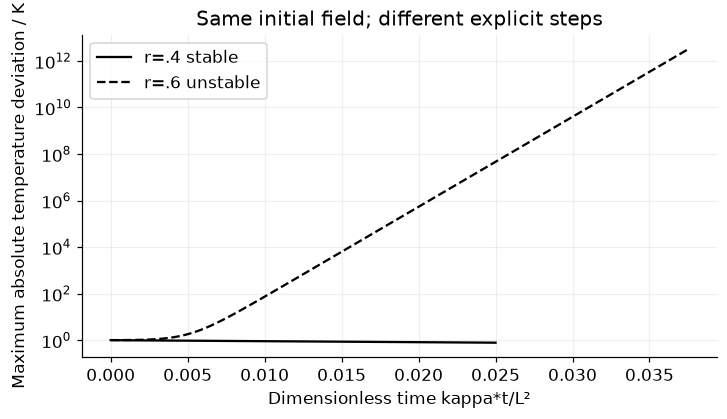

In [4]:
stable=evolve(initial,.4,100);unstable=evolve(initial,.6,100)
max_stable=np.max(abs(stable),axis=1);max_unstable=np.max(abs(unstable),axis=1)
assert np.all(max_stable[1:]<=max_stable[:-1]+1e-13)
assert max_unstable[-1]>1e10 and np.allclose(stable[:,[0,-1]],0)
fig,ax=plt.subplots(figsize=(6.5,3.7))
for ratio,maximum,style,label in [(.4,max_stable,'-','r=.4 stable'),(.6,max_unstable,'--','r=.6 unstable')]:
 ax.semilogy(np.arange(101)*ratio*dx**2/length**2,maximum,color='black',ls=style,label=label)
ax.set(xlabel='Dimensionless time kappa*t/L²',ylabel='Maximum absolute temperature deviation / K',title='Same initial field; different explicit steps');ax.legend();ax.grid(alpha=.2);plt.show()
RESULTS['stable_final_max_K']=float(max_stable[-1]);RESULTS['unstable_final_max_K']=float(max_unstable[-1])


<a id="reference-refinement"></a>
## A known solution and a refinement check

For the initial field sin(pi*x/L), the exact fixed-end continuum solution is exp(-kappa*(pi/L)²*t)*sin(pi*x/L). Compare numerical solutions at the *same* final time with r=.4 on 21, 41 and 81 points. Because dt scales as dx², first-order time error and second-order spatial error both scale as dx² here. The observed error should drop by about four, not arbitrarily to zero in finite precision. This checks the declared ideal equation, not material validity.

A batch of sine initial fields below is a function-to-function reference calculation; no neural operator or PINN is trained. Distinguish inputs indexing a field from coordinates at which a single solution is evaluated.


,points,steps,r,max_error_K
0,21,20,0.4,0.000469
1,41,80,0.4,0.000117
2,81,320,0.4,0.000029


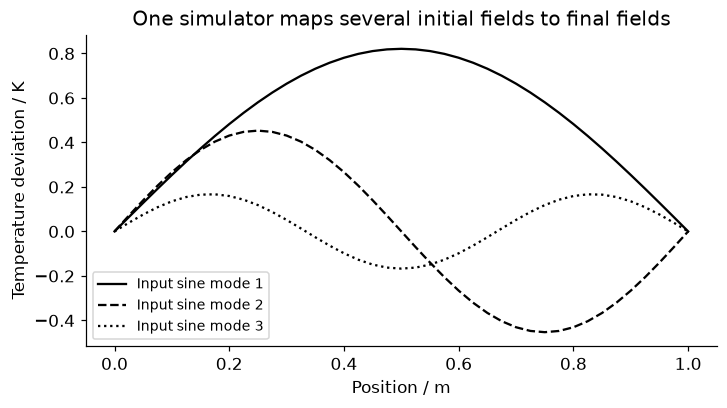

In [5]:
final_time=2.;rows=[]
for points in [21,41,81]:
 grid=np.linspace(0,length,points);spacing=grid[1]-grid[0]
 steps=int(round(final_time*kappa/(.4*spacing**2)));dt=final_time/steps;ratio=kappa*dt/spacing**2
 assert ratio<=.5
 numeric=evolve(np.sin(np.pi*grid/length),ratio,steps)[-1]
 exact=np.exp(-kappa*(np.pi/length)**2*final_time)*np.sin(np.pi*grid/length)
 error=np.max(abs(numeric-exact));rows.append([points,steps,ratio,error])
refinement=pd.DataFrame(rows,columns=['points','steps','r','max_error_K']);display(refinement)
ratios=refinement.max_error_K.to_numpy()[:-1]/refinement.max_error_K.to_numpy()[1:]
assert np.all((ratios>3.8)&(ratios<4.2))
family=np.array([np.sin(j*np.pi*x) for j in [1,2,3]])
outputs=np.array([evolve(field,.4,80)[-1] for field in family])
assert outputs.shape==family.shape and np.allclose(outputs[:,[0,-1]],0)
fig,ax=plt.subplots(figsize=(6.5,3.6))
for j,style in zip(range(3),['-','--',':']):ax.plot(x,outputs[j],color='black',ls=style,label=f'Input sine mode {j+1}')
ax.set(xlabel='Position / m',ylabel='Temperature deviation / K',title='One simulator maps several initial fields to final fields');ax.legend(fontsize=9);plt.show()
RESULTS['refinement_max_errors_K']=refinement.max_error_K.tolist();RESULTS['refinement_error_ratios']=ratios.tolist()


<a id="fft-aliasing"></a>
## Periodic FFT and aliasing: a separate boundary convention

The next signal is periodic on [0,1), unlike the fixed-end rod calculation. NumPy's real FFT stores nonnegative bins. Divide by sample count to normalize coefficients; nonzero, non-Nyquist real cosine amplitudes need an additional factor two. Use `rfftfreq` with the actual spacing for cycles/m; angular wavenumber is 2*pi times this value. The eight-point cosine samples at frequencies 1 and 7 cycles/m coincide, even though the continuous signals differ.

**Predict:** can any algorithm recover which of these two frequencies generated the eight samples without additional assumptions or measurements? Why would wraparound matter if endpoint values were incompatible?


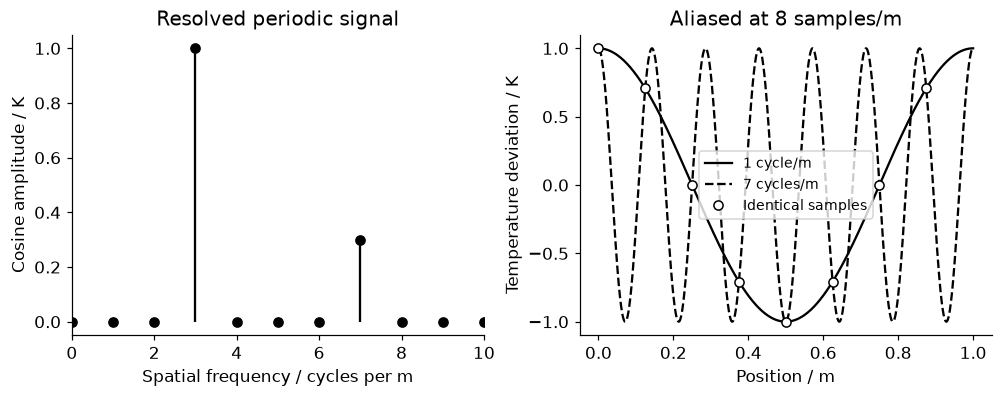

In [6]:
n=64;positions=np.arange(n)/n;signal=np.cos(2*np.pi*3*positions)+.3*np.cos(2*np.pi*7*positions)
freq=np.fft.rfftfreq(n,d=1/n);coeff=np.fft.rfft(signal)/n
amplitude=abs(coeff);amplitude[1:-1]*=2
assert np.isclose(amplitude[3],1.) and np.isclose(amplitude[7],.3)
assert np.allclose(np.fft.irfft(np.fft.rfft(signal),n=n),signal)
samples=np.arange(8)/8;low=np.cos(2*np.pi*samples);high=np.cos(2*np.pi*7*samples)
assert np.allclose(low,high,atol=1e-13)
fine=np.linspace(0,1,1000);fig,axes=plt.subplots(1,2,figsize=(9,3.5))
axes[0].stem(freq,amplitude,linefmt='k-',markerfmt='ko',basefmt=' ');axes[0].set(xlim=(0,10),xlabel='Spatial frequency / cycles per m',ylabel='Cosine amplitude / K',title='Resolved periodic signal')
axes[1].plot(fine,np.cos(2*np.pi*fine),'k-',label='1 cycle/m');axes[1].plot(fine,np.cos(2*np.pi*7*fine),'k--',label='7 cycles/m');axes[1].plot(samples,low,'ko',mfc='white',label='Identical samples')
axes[1].set(xlabel='Position / m',ylabel='Temperature deviation / K',title='Aliased at 8 samples/m');axes[1].legend(fontsize=9);plt.show()
RESULTS['fft_amplitudes_3_and_7']=[float(amplitude[3]),float(amplitude[7])];RESULTS['alias_sample_max_difference']=float(np.max(abs(low-high)))


<a id="exercises"></a>
## Exercises and optional hints

1. Approximate an integral of x² on increasingly fine and irregular grids. Keep integration weights separate from a node-average loss.
2. Halve dx at fixed dt. Predict stability before running; then change dt to preserve r.
3. Replace fixed endpoints by periodic ones using array rolls. Check conservation of the discrete sum and explain why this is a different physical problem.
4. Remove the high-frequency component. Explain why an unstable method can appear harmless for a while; do not mistake missing excitation for stability.
5. Compare at a fixed *number of steps* instead of a fixed final time, then explain why that is the wrong refinement comparison.
6. Label a solution network, learned rate model, physics-residual model and operator model by inputs, outputs and conditions. State what validation each would require beyond a training residual.

**Hints:** discrete sum conservation applies to the symmetric unconstrained graph or periodic example, not fixed reservoirs. Irregular meshes may need volume weights and a mass matrix. A PDE residual evaluated at a finite set of points alone is not a guarantee throughout the domain. An operator should generalize across input functions, not merely interpolate coordinates within one field.

**Troubleshooting:** compare final times exactly, inspect boundary values every step and compute r after refinement. The first-order-time/second-order-space statements assume sufficiently smooth solutions. Official [FFT conventions](https://numpy.org/doc/stable/reference/routines.fft.html) and [trapezoidal integration](https://numpy.org/doc/stable/reference/generated/numpy.trapezoid.html) document the numerical operations; stability and the sine reference are derived explicitly here.


In [7]:
summary={'example_id':'code_011','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU',
'concepts_demonstrated':['weighted integration', 'ODE versus PDE worksheet', 'explicit diffusion and boundary conditions', 'time-step stability', 'stencil and graph correspondence', 'sine reference and refinement', 'periodic FFT and aliasing', 'function-to-function operator family'],'results':RESULTS,
'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["weighted integration", "ODE versus PDE worksheet", "explicit diffusion and boundary conditions", "time-step stability", "stencil and graph correspondence", "sine reference and refinement", "periodic FFT and aliasing", "function-to-function operator family"], "elapsed_seconds": 0.315, "example_id": "code_011", "hardware": "Darwin arm64 CPU", "results": {"alias_sample_max_difference": 3.1086244689504383e-15, "fft_amplitudes_3_and_7": [0.9999999999999998, 0.29999999999999993], "integral_N": 1.0, "refinement_error_ratios": [4.013674689216937, 4.003404570821721], "refinement_max_errors_K": [0.0004685594784891167, 0.00011674077118106752, 2.9160373156367214e-05], "stable_final_max_K": 0.7812048334160514, "stencil_matrix_max_error": 1.1102230246251565e-16, "unstable_final_max_K": 3147014177966.4604, "unweighted_node_mean_N_per_m": 0.5433333333333333}, "seed": 202, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "pytho